# 03 · Coherencia geográfica

> Datos **simulados**, fraude **plantado** sobre líneas y empresas ficticias. Ver `00c_simulacion_secciones.ipynb`.
> Con datos reales esto produciría "anomalías a revisar", nunca prueba de fraude.

Los métodos 01 y 02 miran **cómo cambia una línea en el tiempo**. Este mira algo distinto: **¿lo que se cobra es plausible dado por dónde pasa la línea?**
No necesita historia: compara cada línea con lo esperable para su largo en el *mismo mes*.

El razonamiento es de sentido común. Una línea de 8 km no puede tener pasajeros que viajen 20 km. Y una línea de 15 km tendrá una cierta proporción de viajes largos; si una línea de ese tamaño tiene muchos más que sus pares, algo no cierra.

Probamos tres indicadores, de más literal a más general:
1. **Sección máxima** (la idea original del proyecto): proporción de viajes en la sección más alta.
2. **Secciones imposibles** (regla dura): viajes en secciones cuyo tramo empieza más allá del largo del recorrido.
3. **Exceso de secciones altas** (regla blanda): proporción de viajes en secciones 3 o más, comparada con lo que tienen las líneas de largo parecido.

In [1]:
import sys; sys.path.append('../src')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from coherencia import viajes_imposibles, exceso_altas, puntaje_linea
from simular import cargar_config
cfg = cargar_config(); LIM = cfg['secciones']['limites_km']
sim = pd.read_parquet('../data/processed/sim_secciones.parquet')
sim['imp'] = viajes_imposibles(sim, LIM, tol=0.10)
sim['z_altas'] = exceso_altas(sim)
sim['pct_max'] = sim.pct_sec_max
AS_OF, PLACEBO, VENT = '2026-10-01', '2025-12-01', 6   # evaluamos los últimos 6 meses; el placebo es el mismo cálculo a diciembre 2025

def tabla(hasta):
    d = sim[(sim.mes <= hasta) & (sim.mes > pd.Timestamp(hasta) - pd.DateOffset(months=VENT))]
    verdad = d.groupby('linea_id').verdad_fraude_activo.any()      # solo para EVALUAR
    out = pd.DataFrame({c: puntaje_linea(sim, c, hasta, VENT) for c in ['imp', 'z_altas', 'pct_max']})
    return out.join(verdad.rename('fraude')).join(d.groupby('linea_id').largo_km.first()).dropna()

r, nulo = tabla(AS_OF), tabla(PLACEBO)
print(f'Líneas evaluadas: {len(r)} ({r.fraude.sum()} con fraude presente en los últimos {VENT} meses) | placebo (dic 2025): {len(nulo)} líneas, {nulo.fraude.sum()} con fraude')

Líneas evaluadas: 312 (25 con fraude presente en los últimos 6 meses) | placebo (dic 2025): 323 líneas, 0 con fraude


## 1. El indicador literal no sirve en este escenario
Si miramos solo la proporción de viajes en la sección máxima, ¿separa a las líneas con fraude?

In [2]:
for c, n in [('pct_max', 'Sección máxima'), ('imp', 'Secciones imposibles'), ('z_altas', 'Exceso de secciones altas')]:
    print(f'AUC {n:28s}: {roc_auc_score(r.fraude, r[c]):.3f}')

AUC Sección máxima              : 0.449
AUC Secciones imposibles        : 0.640
AUC Exceso de secciones altas   : 0.949


Un AUC de 0,5 es tirar una moneda: **la sección máxima no detecta nada**. No es una falla del método sino de la hipótesis: en nuestra simulación el fraude corre viajes de la sección 1 a la 3 y de la 2 a la 4, así que **nunca llega a la 5**.
Si en la realidad se infla "una o dos secciones", el indicador de sección máxima tampoco serviría. Por eso conviene mirar el conjunto de secciones altas.

## 2. Secciones imposibles: preciso, pero llega poco
La regla es exacta: si hay viajes en una sección que el recorrido no permite, es incoherente. Pero necesita un **margen de tolerancia**, porque el largo del shapefile es un promedio de ramales y puede tener errores.

In [3]:
d = sim[sim.mes > pd.Timestamp(AS_OF) - pd.DateOffset(months=VENT)].copy()
fr = d.groupby('linea_id').verdad_fraude_activo.any()
filas = []
for tol in (0, .1, .25, .5, 1.0):
    d['x'] = viajes_imposibles(d, LIM, tol); f = d.groupby('linea_id').x.mean() > 0
    filas.append({'margen de tolerancia': f'{tol:.0%}', 'líneas marcadas': int(f.sum()), 'con fraude': int((f & fr).sum()), 'falsas alarmas': int((f & ~fr).sum())})
pd.DataFrame(filas)

,margen de tolerancia,líneas marcadas,con fraude,falsas alarmas
0,0%,9,9,0
1,10%,7,7,0
2,25%,5,5,0
3,50%,2,2,0
4,100%,1,1,0


Tiene **cero falsas alarmas** (cuando salta, es casi seguro que hay algo), pero detecta pocas líneas y pierde potencia rápido al ampliar el margen. En datos reales el margen necesario es incierto y sería mayor que en esta simulación, donde el largo del recorrido es exacto.
Además solo puede atrapar líneas **cortas**: en una línea de 40 km las secciones altas siempre son posibles.

## 3. Exceso de secciones altas
Para cada mes ajustamos, entre todas las líneas, cuántos viajes altos (sección 3 o más) esperaríamos según el largo (con una curva suave y robusta, que no se deja arrastrar por el 10 % de atípicas). Lo que cada línea se aparta de esa curva, en unidades de dispersión típica, es su puntaje; luego promediamos los últimos 6 meses.

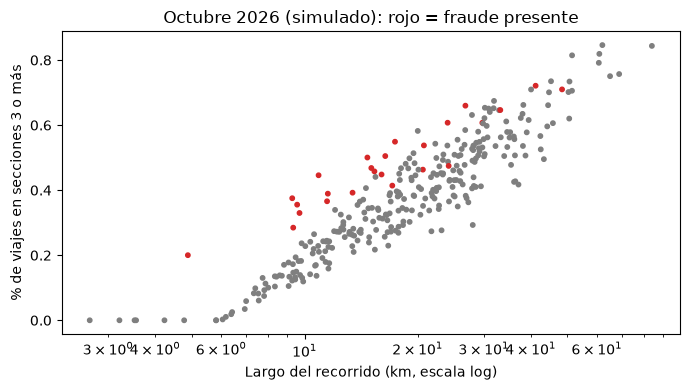

In [4]:
m = sim[sim.mes == AS_OF].copy(); m['altas'] = m[['v3', 'v4', 'v5']].sum(axis=1) / m.viajes
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(m.largo_km, m.altas, s=10, c=m.verdad_fraude_activo.map({True: 'tab:red', False: 'tab:gray'}))
ax.set_xscale('log'); ax.set_xlabel('Largo del recorrido (km, escala log)'); ax.set_ylabel('% de viajes en secciones 3 o más')
ax.set_title('Octubre 2026 (simulado): rojo = fraude presente'); plt.tight_layout()
plt.savefig('../outputs/figures/m03_altas_vs_largo.png', dpi=150); plt.show()

Las líneas con fraude (rojo) tienden a quedar por encima de la nube, pero **se mezclan con líneas sin fraude** que, por su estilo propio, también tienen más viajes largos. Esa heterogeneidad natural es la que limita al método.

### ¿Dónde poner el umbral?
Igual que en los métodos anteriores: con un placebo. Calculamos el mismo puntaje a diciembre de 2025 (sin fraude) y elegimos el percentil 95 de esa distribución, la misma regla que usamos en el método 01. Mostramos también el percentil 99 como comparación.

In [5]:
filas = []
for q in (.90, .95, .99):
    t = nulo.z_altas.quantile(q); f = r.z_altas > t
    tp, fp, fn = int((f & r.fraude).sum()), int((f & ~r.fraude).sum()), int((~f & r.fraude).sum())
    filas.append({'umbral (percentil del placebo)': f'p{int(q*100)}', 'valor': round(t, 2), 'TP': tp, 'FP': fp, 'FN': fn,
                  'precisión': f'{tp/max(tp+fp,1):.0%}', 'recall': f'{tp/(tp+fn):.0%}'})
pd.DataFrame(filas)

,umbral (percentil del placebo),valor,TP,FP,FN,precisión,recall
0,p90,1.40,18,22,7,45%,72%
1,p95,1.97,16,3,9,84%,64%
2,p99,2.28,12,1,13,92%,48%


**Cómo leerlo:** la fila p95 es la regla fijada de antemano. El p99 es más estricto y pierde casos (menos recall); el p90 suma falsas alarmas. Con el p95 el método deja pasar cerca de 1 de cada 3 líneas con fraude: el ruido natural entre líneas (desvío ≈ 1) es comparable a la mitad de la señal del fraude (≈ 2). Como veredicto individual es **moderado**; como **ranking de priorización** rinde mejor:

Top 10: 9 con fraude (90%)
Top 25: 16 con fraude (64%)
Top 50: 21 con fraude (42%)


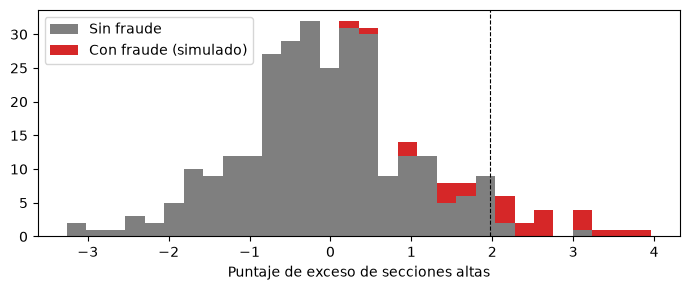

In [6]:
rk = r.sort_values('z_altas', ascending=False)
for k in (10, 25, 50):
    print(f'Top {k}: {int(rk.head(k).fraude.sum())} con fraude ({rk.head(k).fraude.mean():.0%})')
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist([r[~r.fraude].z_altas, r[r.fraude].z_altas], bins=30, stacked=True, color=['tab:gray', 'tab:red'], label=['Sin fraude', 'Con fraude (simulado)'])
ax.axvline(nulo.z_altas.quantile(.95), ls='--', color='k', lw=.8); ax.set_xlabel('Puntaje de exceso de secciones altas'); ax.legend(); plt.tight_layout()
plt.savefig('../outputs/figures/m03_distribucion_puntajes.png', dpi=150); plt.show()

## 4. ¿Funciona igual para cualquier largo?

In [7]:
r['rango_largo_km'] = pd.cut(r.largo_km, [0, 6, 12, 27, 200])
def resumen(d):
    return pd.Series({'líneas': len(d), 'con fraude': int(d.fraude.sum()),
                      'AUC': roc_auc_score(d.fraude, d.z_altas) if 0 < d.fraude.sum() < len(d) else np.nan})
r.groupby('rango_largo_km', observed=True).apply(resumen).round(2)

,líneas,con fraude,AUC
rango_largo_km,,,
"(0, 6]",9.0,1.0,1.00
"(6, 12]",70.0,8.0,1.00
"(12, 27]",152.0,12.0,0.93
"(27, 200]",81.0,4.0,0.83


El AUC es alto en todos los rangos, algo menor en las líneas más largas: allí las secciones altas ya son comunes y 20 % de los viajes bajos corridos mueve menos la proporción.
(Los rangos extremos tienen muy pocas líneas con fraude; no hay que sobreinterpretar sus valores.)

## 5. ¿Cubre lo que el control sintético no podía?
El método 02 necesita 36 meses de historia; este no. Veamos qué pasa con las líneas con fraude que el 02 no pudo evaluar.

In [8]:
sc = pd.read_parquet('../data/processed/res_m02_sintetico.parquet')
t95 = nulo.z_altas.quantile(.95)
no02 = r[~r.index.isin(sc.linea_id) & r.fraude]
print(f'Líneas con fraude que el método 02 no puede evaluar: {len(no02)}')
print(f'De ellas, marcadas por este método (p95): {int((no02.z_altas > t95).sum())}')
no02[['largo_km', 'z_altas']].round(2)

Líneas con fraude que el método 02 no puede evaluar: 6
De ellas, marcadas por este método (p95): 5


,largo_km,z_altas
linea_id,,
L099,7.57,2.64
L117,11.53,2.49
L221,20.64,1.04
L239,14.69,3.00
L310,17.40,3.27
L342,10.89,3.96


Complementa **bastante**: rescata la mayoría de los casos que el 02 no puede evaluar (5 de 6 en esta simulación; con 6 casos el dato es frágil). Aun así, no reemplaza al control sintético: su umbral es el mismo para todas las líneas y no estima montos.

## 6. Combinar las dos reglas

In [9]:
marca = (r.z_altas > t95) | (r.imp > 0)
tp, fp, fn = int((marca & r.fraude).sum()), int((marca & ~r.fraude).sum()), int((~marca & r.fraude).sum())
print(f'Blanda (p95) OR dura: TP={tp} FP={fp} FN={fn} | precisión {tp/(tp+fp):.0%}, recall {tp/(tp+fn):.0%}')
r.assign(marca=marca)[['imp', 'z_altas', 'largo_km', 'marca']].reset_index().to_parquet('../data/processed/res_m03_coherencia.parquet')

Blanda (p95) OR dura: TP=16 FP=3 FN=9 | precisión 84%, recall 64%


## Conclusión y limitaciones
- **La sección máxima, tal como la planteaba la idea original, no sirve** si el fraude infla pocas secciones. Hay que mirar las secciones altas en conjunto.
- **Regla dura:** casi sin falsas alarmas, pero atrapa pocos casos y es sensible a la medición del recorrido.
- **Regla blanda:** buen ranking (AUC ≈ 0,9), veredicto individual moderado. Útil para *priorizar* qué revisar, no para decidir.
- **No usa la historia de cada línea**, a diferencia de los métodos 01 y 02: en principio puede evaluar una línea nueva (acá rescató 5 de 6 casos que el 02 no podía evaluar). Su punto débil es el opuesto: si muchas líneas de un mismo largo inflan a la vez, la curva de lo "normal" sube con ellas y el exceso se achica.
- **Supuesto de la simulación:** el largo del recorrido es exacto y no hay shocks geográficos. Con datos reales, recorridos que cambian o se desvían generarían falsas alarmas.
- **Siguiente (método 04):** Isolation Forest / LOF sobre todos los rasgos línea-mes a la vez, para ver si un detector genérico de anomalías se acerca a estos.